In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

In [2]:
df=pd.read_csv('Merge_data_v5_selected.csv')

In [37]:
del df['Unnamed: 0']

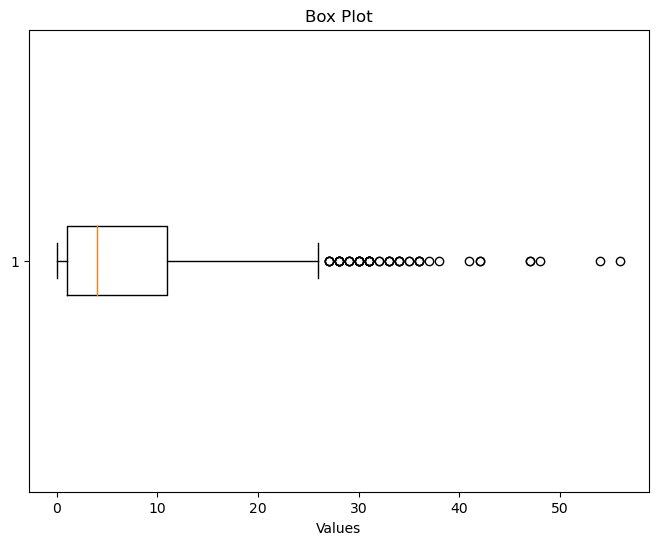

In [24]:
plt.figure(figsize=(8, 6))
plt.boxplot(df['total_count'], vert=False)  # vert=False for horizontal orientation
plt.xlabel('Values')
plt.title('Box Plot')
plt.show()

In [34]:
mean = np.mean(df['total_count'])
std_dev = np.std(df['total_count'])

threshold = 3

outliers = df['total_count'][((df['total_count'] - mean) / std_dev) > threshold]

outliers.count()

39

In [31]:
Q1 = np.percentile(df['total_count'], 25)
Q3 = np.percentile(df['total_count'], 75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df['total_count'][(df['total_count'] < lower_bound) | (df['total_count'] > upper_bound)]

print("Outlier data points:")
outliers

Outlier data points:


16      36.0
111     31.0
204     28.0
240     35.0
366     31.0
444     31.0
499     34.0
500     27.0
501     36.0
625     33.0
659     32.0
712     31.0
714     30.0
719     28.0
752     29.0
874     27.0
876     31.0
884     30.0
885     41.0
886     54.0
887     28.0
888     56.0
889     31.0
895     38.0
898     36.0
900     47.0
901     33.0
911     27.0
1010    29.0
1032    28.0
1134    30.0
1294    30.0
1392    31.0
1416    28.0
1453    29.0
1455    35.0
1458    28.0
1475    30.0
1488    34.0
1493    30.0
1494    42.0
1496    32.0
1497    33.0
1498    47.0
1499    48.0
1500    34.0
1502    27.0
1503    37.0
1504    34.0
1505    36.0
1519    42.0
1520    29.0
1521    33.0
Name: total_count, dtype: float64

In [32]:
outliers.count()

53

In [25]:
df['anomaly'] = df['total_count'].apply(lambda x: 0 if 0 <= x <= 26 else 1)

In [28]:
df['anomaly'][df['anomaly']==1].shape

(53,)

In [38]:
drop_features = ['total_count','anomaly']
target_feature = 'anomaly'

In [39]:
X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [60]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [61]:
from sklearn.metrics import accuracy_score,confusion_matrix
clf = RandomForestClassifier(n_estimators=50, random_state=42)
clf.fit(X_train, y_train)

# Predict anomalies
y_pred = clf.predict(X_test)

# Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9673539518900344


In [62]:
y_test.value_counts()

0    562
1     20
Name: anomaly, dtype: int64

In [63]:
y_train.value_counts()

0    1323
1      33
Name: anomaly, dtype: int64

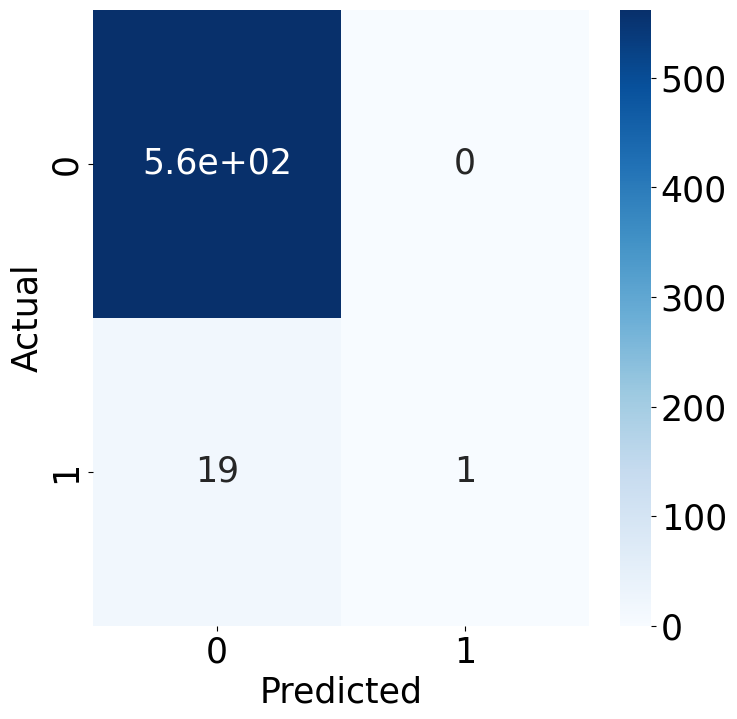

In [64]:
import seaborn as sns
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix, annot=True, cmap='Blues', xticklabels=[0,1], yticklabels=[0,1],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25) 
plt.show()